In [ ]:
# 1. Khai báo tất cả thư viện
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient
import warnings
import math

# Cấu hình bỏ qua thông báo cảnh báo
warnings.filterwarnings("ignore")

# 2. Khởi tạo kết nối đến MongoDB Atlas
# Lưu ý: Khi nộp bài, hãy sử dụng biến môi trường hoặc thư viện python-dotenv để bảo mật mật khẩu
client = MongoClient('mongodb+srv://<username>:<password>@cluster0.mongodb.net/')
db = client['ecom_data_lab']

## **Mục tiêu 5: Đánh giá mức độ nhạy cảm về giá giữa các Danh mục sản phẩm chủ lực.**

### Mục tiêu phân tích

> Đánh giá mức độ nhạy cảm về giá của các danh mục sản phẩm chủ lực trên Lazada, thông qua việc so sánh lượng bán trung bình giữa trạng thái **không giảm giá (0%)** và **giảm giá 20–30%**. Đồng thời, kiểm chứng sâu hơn tại danh mục nhạy cảm nhất liệu việc giảm giá có thực sự kéo theo doanh thu tăng hay chỉ đơn thuần tăng sản lượng.


### Các trường dữ liệu (Metrics) được sử dụng

> - **Giam_gia_num** *(Numerical/Liên tục → Categorical sau lọc)*: Biến điều kiện phân tách hai nhóm đối lập — không giảm giá (= 0%) và giảm giá mạnh (20–30%) — tạo ra hai trạng thái kiểm soát rõ ràng để đo phản ứng sức mua.
> - **Da_ban_num** *(Numerical/Liên tục)*: Biến đo lường sức mua thực tế (volume), phản ánh hành vi khách hàng khi giá thay đổi. Được tính trung bình (`avg_sold`) theo từng nhóm danh mục và trạng thái giá.
> - **Danh mục** *(Categorical/Phân loại)*: Trục phân tầng để so sánh mức độ nhạy cảm giữa các ngành hàng — Top 5 danh mục có lượng bán cao nhất ở trạng thái giảm giá được chọn làm đối tượng phân tích chính.
> - **Gia_num** → `Gia_num` *(Numerical/Liên tục)*: Biến bổ sung tại Biểu đồ 5.2, đo giá bán trung bình (`avg_price`) giữa hai trạng thái để kiểm tra liệu giảm giá có kéo mặt bằng giá xuống đáng kể hay không.
> - **Doanh_thu** → `Doanh_thu = Gia_num × Da_ban_num` *(Numerical/Phái sinh)*: Biến tổng hợp tính doanh thu ước tính theo từng sản phẩm, sau đó lấy trung bình (`avg_revenue`) để kiểm chứng giả thuyết: giảm giá tăng sản lượng nhưng chưa chắc tăng doanh thu thực.

### Giải thích lý do phù hợp

> Mục tiêu này giải quyết trực tiếp bài toán **phân bổ ngân sách khuyến mãi** — một trong những quyết định chiến lược quan trọng nhất đối với nhà bán hàng trên sàn thương mại điện tử.
>
> Thứ nhất, về **độ nhạy cảm giá**, không phải danh mục nào cũng phản ứng như nhau trước khuyến mãi. Việc sử dụng Dumbbell Chart so sánh song song lượng bán ở hai mức giá giúp định lượng chính xác "độ co giãn" của từng ngành hàng, từ đó xác định danh mục nào xứng đáng đầu tư mã giảm giá hơn.
>
> Thứ hai, về **hiệu quả doanh thu thực**, chỉ nhìn vào sản lượng là chưa đủ. Biểu đồ 5.2 kiểm chứng thêm liệu danh mục nhạy cảm nhất có thực sự sinh lời nhiều hơn khi giảm giá hay không — tránh bẫy "bán nhiều hơn nhưng lời ít hơn" do giá bán bị kéo xuống quá sâu.


### Price Sensitivity Analysis (SMART)

**Cụ thể:**  
So sánh lượng bán trung bình của Top 5 danh mục giữa 2 trạng thái:
- Không giảm giá (0%)  
- Giảm giá mạnh (20–30%)  

Kiểm chứng sâu tại danh mục nhạy cảm nhất: so sánh giá bán TB và doanh thu TB giữa 2 trạng thái

**Đo lường:**  
- Xác định danh mục có delta lượng bán lớn nhất (số tuyệt đối và % tăng)  
- So sánh doanh thu trung bình: Giảm giá vs. Không giảm giá tại danh mục trọng điểm  

**Khả thi:**  
- Dùng MongoDB (aggregation: ép kiểu, lọc 2 trạng thái, group by Danh mục)  
- Dùng Pandas (pivot, sort, head(5)) để xử lý và trực quan hóa  

**Liên quan:**  
Giúp nhà bán hàng ra quyết định:  
- Danh mục nhạy cảm cao → ưu tiên chiến dịch Flash Sale  
- Danh mục kém nhạy cảm → tập trung vào chất lượng & thương hiệu thay vì giảm giá  

**Thời hạn:**  
Dữ liệu đến 03/2026 → định hướng phân bổ ngân sách khuyến mãi cho quý tiếp theo

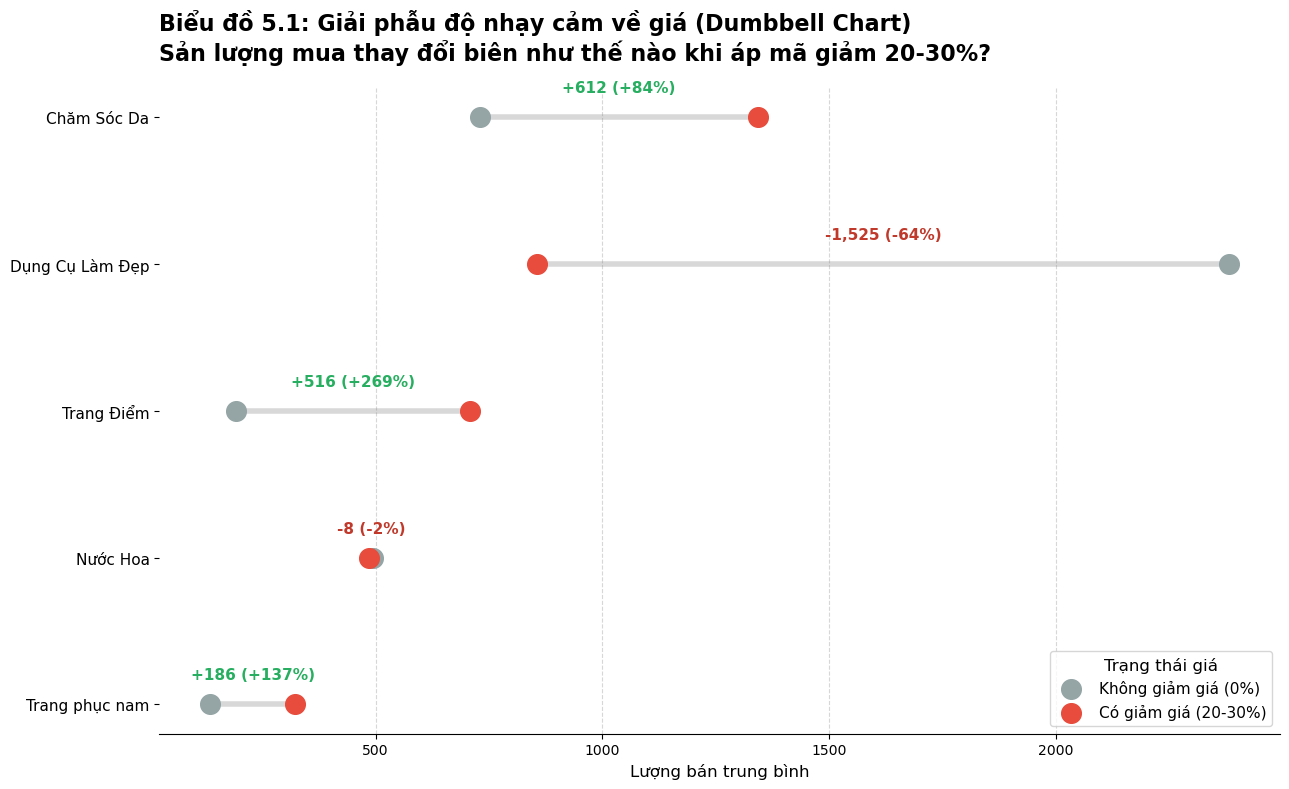

Insight nóng: 'Chăm Sóc Da' là mỏ vàng Marketing. Chỉ với việc giảm giá 20-30%, lượng xuất đơn tăng sốc tới +612 sản phẩm/shop!


In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

collection_sanpham = db["fact_products"]

# --- PIPELINE GOM CHUNG DỮ LIỆU ---
pipeline_dumbbell = [
    # 1. Ép kiểu dữ liệu
    {"$addFields": {
        "Giam_gia_num": {"$convert": {"input": "$Giảm giá", "to": "double", "onError": 0.0, "onNull": 0.0}},
        "Da_ban_num": {"$convert": {"input": "$Đã bán", "to": "int", "onError": 0, "onNull": 0}}
    }},
    # 2. Lọc chỉ lấy 2 trạng thái: Không giảm (0%) hoặc Giảm 20-30%
    {"$match": {
        "$or": [
            {"Giam_gia_num": 0.0},
            {"Giam_gia_num": {"$gte": 0.20, "$lte": 0.30}}
        ]
    }},
    # 3. Phân loại Trạng thái
    {"$project": {
        "Danh mục": 1,
        "Da_ban_num": 1,
        "Trang_thai": {
            "$cond": [{"$eq": ["$Giam_gia_num", 0.0]}, "Khong_giam", "Giam_20_30"]
        }
    }},
    # 4. Gom nhóm tính mức bán trung bình theo Danh mục + Trạng thái
    {"$group": {
        "_id": {"Danh mục": "$Danh mục", "Trang_thai": "$Trang_thai"},
        "avg_sold": {"$avg": "$Da_ban_num"}
    }}
]

cursor = collection_sanpham.aggregate(pipeline_dumbbell)
df_raw = pd.DataFrame([
    {"Danh mục": doc["_id"]["Danh mục"], "Trạng thái": doc["_id"]["Trang_thai"], "Lượng bán TB": doc["avg_sold"]}
    for doc in cursor
])

if df_raw.empty:
    print("Không có dữ liệu phù hợp.")
else:
    # Pivot dữ liệu 
    df_pivot = df_raw.pivot(index="Danh mục", columns="Trạng thái", values="Lượng bán TB").fillna(0)
    
    # Lấy Top 5 Danh mục có lượng bán cao nhất khi giảm giá
    df_top5 = df_pivot.sort_values(by="Giam_20_30", ascending=False).head(5)
    
    # Đảo ngược lại thứ tự để Top 1 nằm trên cùng
    df_top5 = df_top5.iloc[::-1]

    # --- VẼ BIỂU ĐỒ DUMBBELL CHART THÔNG MINH ---
    plt.figure(figsize=(13, 8))

    # Tạo trục Y dạng số học để dễ điều khiển tọa độ
    y_pos = range(len(df_top5))

    # Định nghĩa màu sắc
    color_sale = "#e74c3c"   # Đỏ: Có giảm giá 20-30%
    color_nosale = "#95a5a6" # Xám: Không giảm giá 

    # 1. Vẽ các đường nối ngang (Dumbbell bar)
    plt.hlines(y=y_pos, 
               xmin=df_top5['Khong_giam'], 
               xmax=df_top5['Giam_20_30'], 
               color='grey', alpha=0.3, linewidth=4)

    # 2. Vẽ điểm đầu "Không giảm giá"
    plt.scatter(df_top5['Khong_giam'], y_pos, color=color_nosale, s=200, label='Không giảm giá (0%)', zorder=3)
    
    # 3. Vẽ điểm cuối "Giảm 20-30%"
    plt.scatter(df_top5['Giam_20_30'], y_pos, color=color_sale, s=200, label='Có giảm giá (20-30%)', zorder=3)

    # 4. GẮN THÊM TEXT ĐỘ TĂNG GIẢM TRỰC TIẾP LÊN BIỂU ĐỒ
    for i, cat in enumerate(df_top5.index):
        val_k = df_top5.loc[cat, 'Khong_giam']
        val_g = df_top5.loc[cat, 'Giam_20_30']
        diff = val_g - val_k
        
        # Tính % thay đổi (Xử lý nếu giá gốc = 0 để tránh lỗi chia 0)
        pct = (diff / val_k * 100) if val_k > 0 else 0
        
        # Tìm điểm chính giữa của thanh nối để đặt chữ
        mid_x = (val_k + val_g) / 2
        
        # Định format (Tăng = Xanh lá có dấu +, Giảm = Đỏ có dấu -)
        sign = "+" if diff > 0 else ""
        text_color = "#27ae60" if diff > 0 else "#c0392b"
        
        # In con số ngay trên thanh nối (y + 0.15)
        plt.text(mid_x, i + 0.15, f"{sign}{int(diff):,} ({sign}{pct:.0f}%)", 
                 ha='center', va='bottom', color=text_color, fontweight='bold', fontsize=11)

    # Đưa tên danh mục vào trục Y
    plt.yticks(y_pos, df_top5.index, fontsize=11)

    # 5. Cấu hình giao diện chuẩn mực
    plt.title("Biểu đồ 5.1: Giải phẫu độ nhạy cảm về giá (Dumbbell Chart)\nSản lượng mua thay đổi biên như thế nào khi áp mã giảm 20-30%?", 
              fontsize=16, fontweight='bold', loc='left', pad=20)
    plt.xlabel("Lượng bán trung bình", fontsize=12)
    plt.ylabel("")

    # Loại bỏ viền trên, phải, trái cho thoáng
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    # Lưới đứt dọc
    plt.grid(axis='x', linestyle='--', alpha=0.5)

    # Chú thích
    plt.legend(loc='lower right', frameon=True, fontsize=11, title="Trạng thái giá", title_fontsize='12')

    plt.tight_layout()
    plt.show()

    # In luôn dòng insight bên dưới
    top_cat = df_top5.index[-1]
    diff_val = df_top5.loc[top_cat, 'Giam_20_30'] - df_top5.loc[top_cat, 'Khong_giam']
    print(f"Insight nóng: '{top_cat}' là mỏ vàng Marketing. Chỉ với việc giảm giá 20-30%, lượng xuất đơn tăng sốc tới +{int(diff_val):,} sản phẩm/shop!")

### **Lý do chọn biểu đồ**
- Dumbbell Chart được chọn vì nó trực quan hóa đồng thời **hai điểm dữ liệu trên cùng một trục**, giúp so sánh trực tiếp sự thay đổi lượng bán trước và sau giảm giá mà không cần người đọc tự tính toán chênh lệch.
- Việc gắn nhãn delta (+/- số tuyệt đối và %) ngay trên thanh nối giúp định lượng ngay lập tức "độ co giãn" của từng danh mục, tránh phải đọc số từ hai biểu đồ riêng lẻ rồi so sánh thủ công.

### **Nhận xét**
- **Trang phục nam** và **Trang Điểm** là hai danh mục nhạy cảm về giá cao nhất, với mức tăng lần lượt là +186 (+137%) và +516 (+269%) khi áp mã giảm 20–30%. Đây là nhóm khách hàng ra quyết định mua phụ thuộc rất lớn vào kích thích giá.
- **Chăm Sóc Da** cũng phản ứng tích cực với mức tăng +612 (+84%), cho thấy đây là danh mục có nhu cầu tiềm ẩn lớn nhưng khách hàng đang bị kìm hãm bởi mức giá gốc.
- **Dụng Cụ Làm Đẹp** là trường hợp đặc biệt và đáng chú ý nhất: dù có lượng bán tuyệt đối cao nhất khi không giảm giá (~2,100 sản phẩm), lượng bán lại *giảm mạnh* -1,525 (-64%) khi áp mã giảm 20–30%. Điều này gợi ý rằng khách hàng của danh mục này **không nhạy cảm về giá** — họ mua vì nhu cầu thực sự và không cần kích thích khuyến mãi.
- **Nước Hoa** gần như không phản ứng với giảm giá (-8, -2%), cho thấy đây là danh mục mang tính **quyết định cảm xúc/thương hiệu** hơn là quyết định giá cả.

### **Kết luận**
- Không phải danh mục nào cũng cần chiến lược giảm giá. Ngân sách khuyến mãi nên được ưu tiên tập trung vào **Trang Điểm** và **Trang phục nam** — nơi mà mỗi đồng chi cho mã giảm giá tạo ra phản ứng sức mua lớn nhất, tức ROI khuyến mãi cao nhất.
- Với **Dụng Cụ Làm Đẹp** và **Nước Hoa**, việc liên tục giảm giá không những không kích cầu mà còn có nguy cơ làm xói mòn định vị thương hiệu và giảm biên lợi nhuận một cách không cần thiết. Chiến lược phù hợp hơn là đầu tư vào chất lượng hình ảnh sản phẩm, nội dung mô tả và dịch vụ sau bán.
- Kết quả bất thường của **Dụng Cụ Làm Đẹp** đặt ra một giả thuyết cần kiểm chứng: liệu các sản phẩm *có* giảm giá trong danh mục này có mức giá gốc thấp hơn, dẫn đến doanh thu thực tế thấp hơn dù không giảm giá? Đây là lý do Biểu đồ 5.2 được thiết kế để trả lời tiếp câu hỏi này.

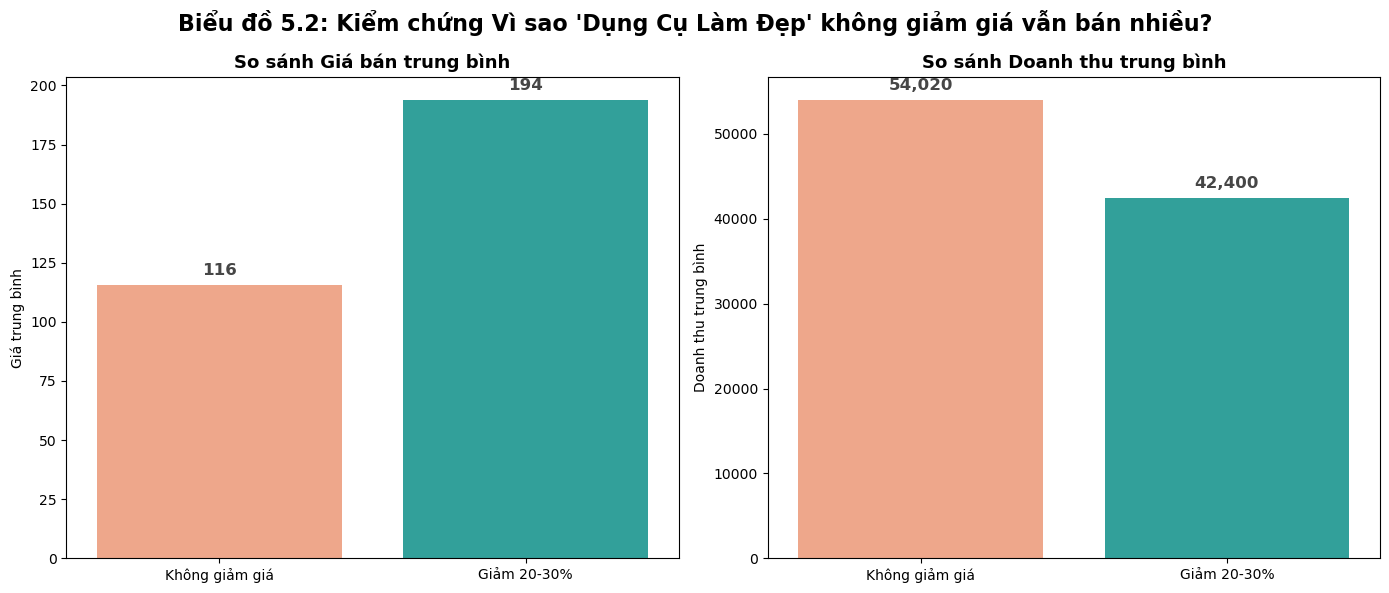

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# BIỂU ĐỒ 5.2: Kiểm chứng giả thuyết Giá & Doanh thu của "Dụng Cụ Làm Đẹp"
target_category = "Dụng Cụ Làm Đẹp"

pipeline_price_revenue = [
    # 1. Ép kiểu dữ liệu (chuẩn bị thêm cột Giá)
    {"$addFields": {
        "Giam_gia_num": {"$convert": {"input": "$Giảm giá", "to": "double", "onError": 0.0, "onNull": 0.0}},
        "Da_ban_num": {"$convert": {"input": "$Đã bán", "to": "int", "onError": 0, "onNull": 0}},
        "Gia_num": {"$convert": {"input": "$Giá", "to": "double", "onError": 0.0, "onNull": 0.0}}
    }},
    # 2. Lọc danh mục và 2 trạng thái cần so sánh
    {"$match": {
        "Danh mục": target_category,
        "$or": [
            {"Giam_gia_num": 0.0},
            {"Giam_gia_num": {"$gte": 0.20, "$lte": 0.30}}
        ]
    }},
    # 3. Tính toán Doanh thu = Giá * Đã bán và Gắn nhãn
    {"$project": {
        "Gia_num": 1,
        "Da_ban_num": 1,
        "Doanh_thu": {"$multiply": ["$Gia_num", "$Da_ban_num"]},
        "Trang_thai": {
            "$cond": [{"$eq": ["$Giam_gia_num", 0.0]}, "Không giảm giá", "Giảm 20-30%"]
        }
    }},
    # 4. Tính trung bình Giá và Doanh thu
    {"$group": {
        "_id": "$Trang_thai",
        "avg_price": {"$avg": "$Gia_num"},
        "avg_revenue": {"$avg": "$Doanh_thu"}
    }},
    {"$sort": {"_id": -1}} # Sắp xếp để "Không giảm giá" đứng trước
]

cursor = collection_sanpham.aggregate(pipeline_price_revenue)
df_hypothesis = pd.DataFrame(list(cursor))

if not df_hypothesis.empty:
    df_hypothesis.rename(columns={"_id": "Trạng thái"}, inplace=True)
    
    # Tạo 2 biểu đồ nằm cạnh nhau
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Biểu đồ 3A: So sánh Giá Trung Bình
    sns.barplot(data=df_hypothesis, x="Trạng thái", y="avg_price", palette=["#FFA07A", "#20B2AA"], ax=axes[0])
    axes[0].set_title("So sánh Giá bán trung bình", fontweight='bold', fontsize=13)
    axes[0].set_ylabel("Giá trung bình")
    axes[0].set_xlabel("")
    for p in axes[0].patches:
        axes[0].annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=12, fontweight='bold', color='#464646', xytext=(0, 5), textcoords='offset points')

    # Biểu đồ 3B: So sánh Doanh Thu Trung Bình
    sns.barplot(data=df_hypothesis, x="Trạng thái", y="avg_revenue", palette=["#FFA07A", "#20B2AA"], ax=axes[1])
    axes[1].set_title("So sánh Doanh thu trung bình", fontweight='bold', fontsize=13)
    axes[1].set_ylabel("Doanh thu trung bình")
    axes[1].set_xlabel("")
    for p in axes[1].patches:
        axes[1].annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=12, fontweight='bold', color='#464646', xytext=(0, 5), textcoords='offset points')

    fig.suptitle(f"Biểu đồ 5.2: Kiểm chứng Vì sao '{target_category}' không giảm giá vẫn bán nhiều?", fontweight='bold', fontsize=16)
    plt.tight_layout()
    plt.show()
    
    

### **Lý do chọn biểu đồ**
- Grouped Bar Chart (2 cột song song) được chọn vì mục tiêu ở đây là **kiểm chứng nhân quả** — không chỉ so sánh một chỉ số mà phải đối chiếu đồng thời hai chiều: giá bán và doanh thu. Việc đặt hai biểu đồ cạnh nhau giúp người đọc nhận ra ngay sự nghịch lý mà một biểu đồ đơn lẻ không thể hiện được.
- Bar Chart phù hợp hơn Line Chart hay Scatter Plot trong trường hợp này vì chỉ có **2 nhóm so sánh rời rạc** (Không giảm giá vs. Giảm 20–30%), không có tính liên tục về thời gian hay phân phối cần thể hiện.

### **Nhận xét**
- **Về giá bán trung bình**: Nhóm không giảm giá có giá trung bình chỉ 116k, trong khi nhóm giảm 20–30% có giá trung bình lên tới 194k — chênh lệch gần **1.7 lần**. Điều này tiết lộ bản chất thực sự của hiện tượng ở Biểu đồ 5.1: lượng bán cao của nhóm "không giảm giá" không phải vì khách hàng trung thành hay thương hiệu mạnh, mà đơn giản là vì **đây vốn là những mặt hàng giá rẻ** — khách hàng mua ngay mà không cần kích thích thêm.
- **Về doanh thu trung bình**: Nhóm giảm giá 20–30% tạo ra doanh thu trung bình 42,400k, thấp hơn nhóm không giảm giá (54,020k) khoảng ~11,600k. Tuy nhiên, cần nhìn nhận đúng bản chất: nhóm giảm giá đang bán các sản phẩm có giá gốc cao hơn (~194k), nên dù doanh thu trung bình thấp hơn, đây vẫn là những giao dịch có **giá trị đơn hàng lớn hơn đáng kể** so với nhóm không giảm giá (~116k).
- Nói cách khác, hai nhóm này thực chất đang phục vụ **hai phân khúc khách hàng hoàn toàn khác nhau**: nhóm không giảm giá thu hút khách mua đồ bình dân giá rẻ với tần suất cao, còn nhóm giảm giá 20–30% đang kéo những khách hàng vốn nhắm vào sản phẩm cao cấp hơn nhưng cần thêm một cú hích về giá để chốt đơn.

### **Kết luận**
- Biểu đồ 5.2 giải mã hoàn toàn nghịch lý ở Biểu đồ 5.1: **Dụng Cụ Làm Đẹp không giảm giá vẫn bán được nhiều** không phải vì sản phẩm xuất sắc, mà vì bản chất chúng là hàng giá rẻ (~116k) — vốn dĩ không cần khuyến mãi để thuyết phục khách mua.
- Ngược lại, những sản phẩm giảm 20–30% trong cùng danh mục có giá gốc cao hơn nhiều (~194k), và việc giảm giá đang đóng vai trò **hạ thấp rào cản tâm lý** để khách hàng sẵn sàng chi nhiều hơn cho một lần mua. Chiến lược này không tệ — nó đang nhắm đúng đối tượng.
- Khuyến nghị: Nhà bán hàng nên **duy trì song song cả hai chiến lược** — để nguyên giá với hàng bình dân (để tối đa hóa volume và xoay vòng vốn nhanh), đồng thời áp dụng mã giảm 20–30% có chọn lọc cho các sản phẩm cao cấp hơn nhằm kích hoạt nhóm khách hàng có khả năng chi tiêu cao nhưng cần thêm động lực.

## **Mục tiêu 6: Xác định 'Danh mục Cốt lõi' (Bán chạy, Đánh giá cao, Ít phụ thuộc giảm giá).**

### Mục tiêu phân tích

> Xác định "Danh mục Cốt lõi" trên sàn Lazada — tức các danh mục đồng thời thỏa mãn ba tiêu chí: **bán chạy** (volume cao), **được đánh giá cao** (rating > 4.8) và **ít phụ thuộc vào giảm giá** (discount thấp hơn mặt bằng chung). Đây là những danh mục có sức cạnh tranh bền vững nhất, không cần "mua" doanh số bằng khuyến mãi mà vẫn duy trì được lòng tin của khách hàng.

### Các trường dữ liệu (Metrics) được sử dụng

> - **Giảm giá** → `avg_discount` *(Numerical/Liên tục)*: Tỷ lệ giảm giá trung bình theo danh mục, đóng vai trò trục X trong Bubble Chart — thước đo mức độ "phụ thuộc khuyến mãi" của từng ngành hàng.
> - **Điểm đánh giá** → `avg_rating` *(Numerical/Liên tục)*: Điểm đánh giá trung bình theo danh mục, đóng vai trò trục Y — thước đo uy tín và chất lượng cảm nhận từ phía khách hàng.
> - **Đã bán** → `avg_sold` *(Numerical/Liên tục)*: Lượng bán trung bình theo danh mục, được mã hóa thành **kích thước bong bóng** trong Bubble Chart — thể hiện quy mô sức mua thực tế.
> - **Doanh thu** → `avg_revenue = Giá × Đã bán` *(Numerical/Phái sinh)*: Doanh thu trung bình ước tính, bổ sung chiều thứ tư để đánh giá giá trị kinh tế thực của từng danh mục bên cạnh volume thuần túy.
> - **Danh mục** *(Categorical/Phân loại)*: Đơn vị phân tích — mỗi bong bóng đại diện cho một danh mục sản phẩm trên toàn sàn.

### Giải thích lý do phù hợp

> **Giảm giá** và **Điểm đánh giá** được chọn làm hai trục chính vì chúng đại diện cho hai chiến lược cạnh tranh đối lập nhau: cạnh tranh bằng giá (discount cao) và cạnh tranh bằng chất lượng (rating cao). Một danh mục nằm ở góc phần tư "rating cao — discount thấp" chứng minh rằng nó không cần dựa vào khuyến mãi để giữ chân khách hàng, tức là có nền tảng bền vững hơn.
>
> **Đã bán** được đưa vào dưới dạng kích thước bong bóng thay vì một trục riêng, vì nếu dùng trục thứ ba sẽ phá vỡ cấu trúc quadrant — trong khi kích thước bong bóng vẫn truyền tải được thông tin volume mà không làm mất đi cấu trúc phân tầng 4 góc phần tư.
>
> **Điểm đánh giá** trong Biểu đồ 6.2 được phân tích dưới dạng **phân bố mật độ** thay vì chỉ lấy giá trị trung bình, vì một danh mục "cốt lõi" cần chứng minh sự ổn định — rating cao đều đặn trên toàn bộ sản phẩm — chứ không chỉ nhờ vài sản phẩm đỉnh kéo trung bình lên.

### Core Category Analysis (SMART)

**Cụ thể:**  
Xác định danh mục thỏa mãn đồng thời 3 tiêu chí:
- Rating trung bình > 4.8 (ngưỡng uy tín cao)
- Discount trung bình < mặt bằng chung toàn sàn
- Lượng bán trung bình thuộc top (bong bóng lớn)

Kiểm chứng thêm tính ổn định chất lượng của danh mục được chọn qua phân bố mật độ rating so với toàn sàn

**Đo lường:**
- Quadrant Bubble Chart: xác định danh mục nằm ở góc phần tư "rating cao — discount thấp"
- KDE Plot: so sánh phân bố điểm đánh giá của danh mục cốt lõi vs. mặt bằng chung

**Khả thi:**
- Dùng MongoDB (aggregation: lọc NaN, tính avg theo danh mục)
- Dùng Pandas + Seaborn (scatterplot với size encoding, kdeplot chồng lớp)

**Liên quan:**  
Giúp nhà bán hàng xác định:
- Danh mục nào đáng đầu tư dài hạn mà không cần liên tục đốt ngân sách khuyến mãi
- Danh mục nào đang tăng trưởng bền vững nhờ chất lượng thực sự

**Thời hạn:**  
Dữ liệu đến 03/2026 → định hướng chiến lược danh mục cho quý tiếp theo

Đã xử lý và tính trung bình trực tiếp trên MongoDB thành công!


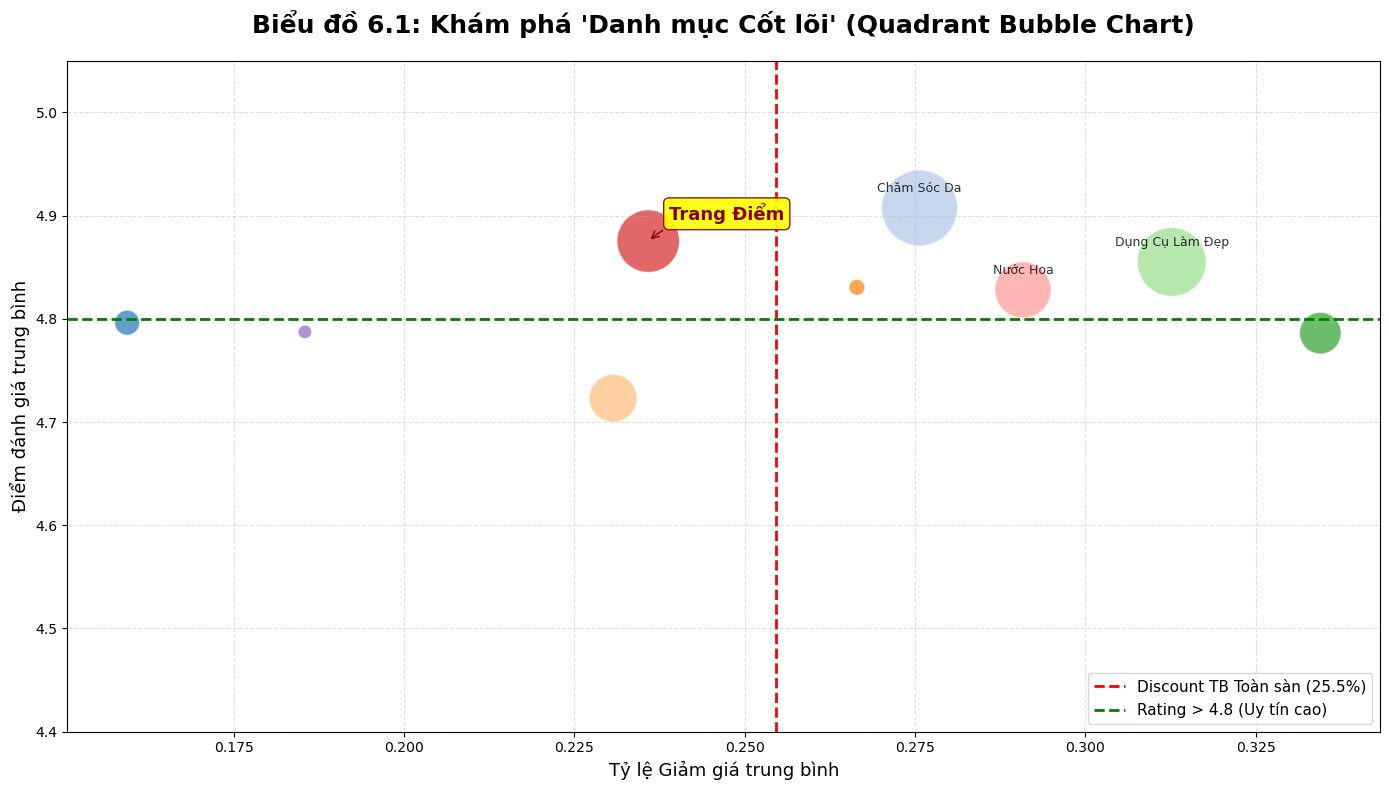

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient
import math # Thư viện để nhận diện giá trị NaN
import warnings
warnings.filterwarnings("ignore")

# 1. Khởi tạo kết nối
collection_sanpham = db['fact_products']

# --- PIPELINE XỬ LÝ NaN VÀ TÍNH TRUNG BÌNH TRỰC TIẾP TRÊN MONGO ---
pipeline_stats = [
    # Bước 1: LỌC BỎ CÁC DÒNG CÓ CHỨA NaN HOẶC KHÔNG PHẢI LÀ SỐ
    {"$match": {
        "Danh mục": {"$type": "string", "$ne": ""},
        "Điểm đánh giá": {"$type": "number", "$ne": float('nan')}, # Chặn đứng thủ phạm NaN
        "Giảm giá": {"$type": "number", "$ne": float('nan')},
        "Đã bán": {"$type": "number", "$ne": float('nan')},
        "Giá": {"$type": "number", "$ne": float('nan')}
    }},
    
    # Bước 2: Tính doanh thu
    {"$addFields": {
        "Doanh_thu": {"$multiply": ["$Giá", "$Đã bán"]}
    }},
    
    # Bước 3: Tính trung bình theo Danh mục
    {"$group": {
        "_id": "$Danh mục",
        "avg_discount": {"$avg": "$Giảm giá"},
        "avg_rating": {"$avg": "$Điểm đánh giá"},
        "avg_sold": {"$avg": "$Đã bán"},
        "avg_revenue": {"$avg": "$Doanh_thu"}
    }}
]

# Chạy Pipeline
cursor_stats = collection_sanpham.aggregate(pipeline_stats)
df_stats = pd.DataFrame(list(cursor_stats))
df_stats.rename(columns={"_id": "Danh mục"}, inplace=True)

# 2. Xử lý và tìm Danh mục Cốt lõi
if df_stats.empty:
    print("❌ LỖI: Dữ liệu vẫn trống, có gì đó sai sai.")
else:
    print("Đã xử lý và tính trung bình trực tiếp trên MongoDB thành công!")
    market_avg_discount = df_stats['avg_discount'].mean()
    market_avg_rating = df_stats['avg_rating'].mean()

    star_candidates = df_stats[(df_stats['avg_rating'] > 4.8) & (df_stats['avg_discount'] < market_avg_discount)]
    
    if not star_candidates.empty:
        star_category = star_candidates.sort_values(by='avg_sold', ascending=False).iloc[0]
        star_cat_name = star_category['Danh mục']
    else:
        star_cat_name = df_stats.sort_values(by=['avg_rating', 'avg_sold'], ascending=False).iloc[0]['Danh mục']
        
    # 3. VẼ BIỂU ĐỒ QUADRANT BUBBLE CHART
    plt.figure(figsize=(14, 8))
    scatter = sns.scatterplot(
        data=df_stats, 
        x="avg_discount", 
        y="avg_rating", 
        size="avg_sold", 
        hue="Danh mục",
        sizes=(100, 3000), 
        alpha=0.7, 
        palette="tab20",
        legend=False
    )

    # Kẻ đường cơ sở
    plt.axvline(x=market_avg_discount, color='red', linestyle='--', linewidth=2, label=f'Discount TB Toàn sàn ({market_avg_discount:.1%})')
    plt.axhline(y=4.8, color='green', linestyle='--', linewidth=2, label='Rating > 4.8 (Uy tín cao)')

    # Zoom cận cảnh trục Y để thấy rõ các góc phần tư
    plt.ylim(4.4, 5.05)

    # Highlight bong bóng
    for i, row in df_stats.iterrows():
        if row['Danh mục'] == star_cat_name:
            plt.annotate(
                f"{row['Danh mục']}", 
                (row['avg_discount'], row['avg_rating']),
                xytext=(15, 15), textcoords='offset points',
                fontsize=13, fontweight='bold', color='darkred',
                bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="darkred", alpha=0.9),
                arrowprops=dict(arrowstyle="->", color="darkred", connectionstyle="arc3,rad=0.2")
            )
        else:
            if row['avg_sold'] > df_stats['avg_sold'].median():
                plt.text(row['avg_discount'], row['avg_rating'] + 0.015, row['Danh mục'], 
                         horizontalalignment='center', size=9, color='black', alpha=0.8)

    plt.title("Biểu đồ 6.1: Khám phá 'Danh mục Cốt lõi' (Quadrant Bubble Chart)", fontsize=18, fontweight='bold', pad=20)
    plt.xlabel("Tỷ lệ Giảm giá trung bình", fontsize=13)
    plt.ylabel("Điểm đánh giá trung bình", fontsize=13)
    plt.legend(loc='lower right', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

### **Lý do chọn biểu đồ**
- Quadrant Bubble Chart được chọn vì mục tiêu cần **đánh giá đồng thời 3 chiều** trên một khung nhìn duy nhất: mức độ phụ thuộc khuyến mãi (trục X), uy tín chất lượng (trục Y) và quy mô sức mua (kích thước bong bóng). Không có loại biểu đồ đơn chiều nào có thể thay thế được cấu trúc này mà không mất thông tin.
- Hai đường cơ sở (discount TB toàn sàn 25.5% và ngưỡng rating 4.8) chia không gian thành 4 góc phần tư rõ ràng, cho phép **phân loại chiến lược tức thì** mà không cần đọc số — danh mục nào nằm ở góc trên-trái là ứng viên "Cốt lõi" ngay lập tức.

### **Nhận xét**
- **Trang Điểm** được hệ thống tự động xác định là "Danh mục Cốt lõi" vì thỏa mãn đủ 3 tiêu chí: rating > 4.8, discount thấp hơn mặt bằng chung (~23%), và bong bóng có kích thước lớn phản ánh lượng bán cao. Đây là danh mục duy nhất nằm ở **góc phần tư lý tưởng** (trên-trái) với quy mô đáng kể.
- **Chăm Sóc Da** là bong bóng lớn nhất toàn sàn (lượng bán cao nhất), nhưng nằm ở phía **bên phải đường đỏ** — tức discount trung bình vượt mặt bằng chung. Điều này cho thấy danh mục này đang phụ thuộc vào khuyến mãi để duy trì volume, dù rating vẫn giữ được ở mức ~4.9.
- **Dụng Cụ Làm Đẹp** và **Nước Hoa** đều nằm bên phải với discount cao (>27–33%), tức cả hai đang phải "mua" doanh số bằng giảm giá. Kết quả này nhất quán với phát hiện từ Mục tiêu 5 — đây là những danh mục cần xem xét lại chiến lược định giá.
- Hai bong bóng nhỏ phía trên-trái (rating ~4.8, discount ~17%) cho thấy có thể tồn tại các danh mục nhỏ hơn với nền tảng chất lượng tốt nhưng chưa đủ volume để trở thành "Cốt lõi" thực sự.

### **Kết luận**
- **Trang Điểm** là danh mục duy nhất hội tụ đủ ba yếu tố bền vững: bán chạy, được đánh giá cao và không cần phụ thuộc nhiều vào giảm giá. Đây là nền tảng lý tưởng để nhà bán hàng đầu tư dài hạn — tập trung vào chất lượng sản phẩm và trải nghiệm khách hàng thay vì chạy đua khuyến mãi.
- **Chăm Sóc Da** dù có volume lớn nhất nhưng chưa đạt tiêu chuẩn "Cốt lõi" vì đang phụ thuộc discount. Nếu cắt giảm khuyến mãi đột ngột, rủi ro sụt volume là rất cao — đây là tín hiệu cảnh báo về tính bền vững của tăng trưởng trong danh mục này.
- Bức tranh tổng thể cho thấy phần lớn các danh mục lớn trên sàn đang dồn về **góc phần tư phải** (discount cao), phản ánh một thị trường đang cạnh tranh chủ yếu bằng giá. Trong bối cảnh đó, **Trang Điểm** nổi lên như một ngoại lệ tích cực — và đó chính là lý do cần kiểm chứng thêm tính ổn định của nó ở Biểu đồ 6.2.

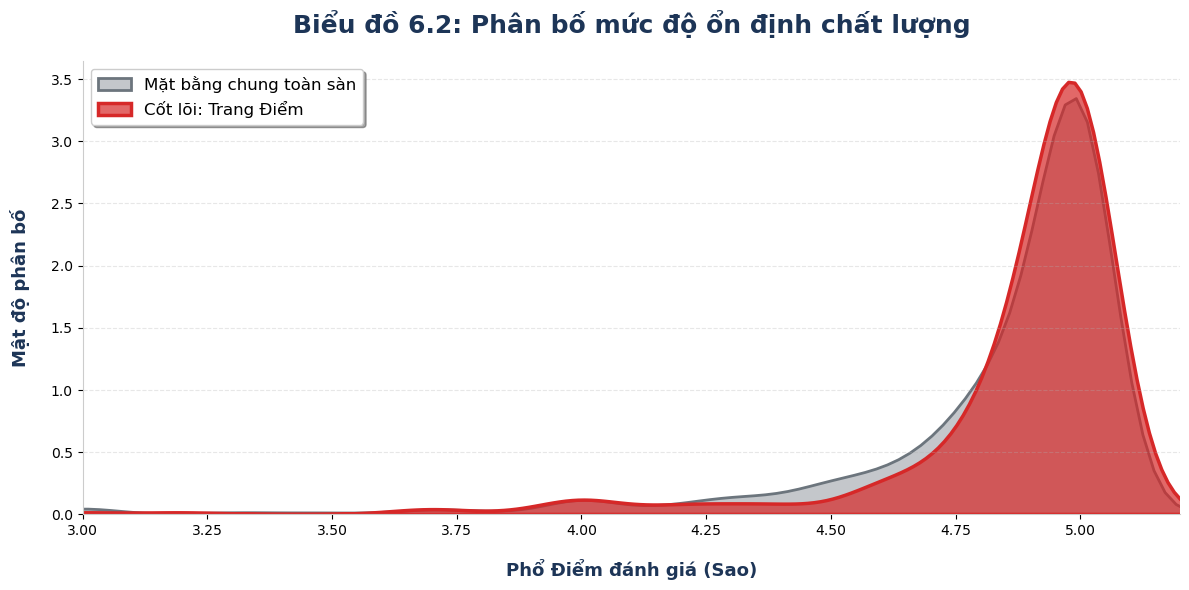

In [5]:
# 1. Khởi tạo kết nối
collection_sanpham = client['ecom_data_lab']['fact_products']

# 2. Pipeline Lấy dữ liệu thô
pipeline_raw = [
    # Lọc các dòng có Điểm đánh giá hợp lệ
    {"$match": {
        "Điểm đánh giá": {"$type": "number", "$ne": float('nan')},
        "Danh mục": {"$type": "string", "$ne": ""}
    }},
    {"$project": {"Danh mục": 1, "Điểm đánh giá": 1, "_id": 0}}
]

df_raw = pd.DataFrame(list(collection_sanpham.aggregate(pipeline_raw)))

if df_raw.empty:
    print("❌ Lỗi: Không kéo được dữ liệu.")
else:
    # LÀM SẠCH CHUỖI: Cắt bỏ mọi khoảng trắng thừa (Fix triệt để lỗi biểu đồ phẳng lì)
    df_raw['Danh mục'] = df_raw['Danh mục'].str.strip()

    # Tách thành 2 tập dữ liệu
    star_data = df_raw[df_raw['Danh mục'] == 'Trang Điểm']['Điểm đánh giá']
    market_data = df_raw[df_raw['Danh mục'] != 'Trang Điểm']['Điểm đánh giá']

    # 3. VẼ BIỂU ĐỒ CHỒNG LÊN NHAU (OVERLAPPING DENSITY PLOT)
    plt.figure(figsize=(12, 6))

    # Vẽ ngọn núi Mặt bằng chung TRƯỚC (Để nó nằm dưới làm nền)
    sns.kdeplot(market_data, fill=True, color="#6c757d", alpha=0.4, linewidth=2, label="Mặt bằng chung toàn sàn")

    # Vẽ ngọn núi Cốt lõi SAU (Để nó đè lên trên, nổi bật nhất)
    sns.kdeplot(star_data, fill=True, color="#d62828", alpha=0.7, linewidth=2.5, label="Cốt lõi: Trang Điểm")

    # Căn chỉnh giao diện
    plt.xlim(3.0, 5.2) # Zoom vào từ 3 sao đến 5 sao
    plt.ylim(bottom=0) # Đáy luôn bắt đầu từ 0
    
    # Ẩn các đường viền trên và phải cho thoáng mắt
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#cccccc')
    ax.spines['bottom'].set_color('#cccccc')

    plt.xlabel('Phổ Điểm đánh giá (Sao)', fontsize=13, fontweight='bold', color='#1d3557', labelpad=15)
    plt.ylabel('Mật độ phân bố', fontsize=13, fontweight='bold', color='#1d3557', labelpad=15)
    
    plt.title('Biểu đồ 6.2: Phân bố mức độ ổn định chất lượng', 
              fontsize=18, fontweight='bold', color='#1d3557', pad=20)
    
    # Đặt Legend (Chú thích) vào vị trí đẹp
    plt.legend(loc='upper left', fontsize=12, frameon=True, shadow=True)
    plt.grid(axis='y', linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.show()

### **Lý do chọn biểu đồ**
- KDE Plot (Kernel Density Estimation) được chọn thay vì Histogram vì mục tiêu ở đây là so sánh **hình dạng phân bố** của hai tập dữ liệu có kích thước khác nhau — nếu dùng Histogram, trục Y sẽ bị lệch hoàn toàn do số lượng sản phẩm của "Trang Điểm" nhỏ hơn nhiều so với toàn sàn, khiến việc chồng lớp mất ý nghĩa.
- Kỹ thuật **chồng lớp hai đường mật độ** (overlapping density) giúp người đọc nhìn ra ngay sự khác biệt về độ tập trung và độ ổn định: nếu đường đỏ có đỉnh cao hơn và hẹp hơn đường xám, danh mục đó có chất lượng đồng đều hơn toàn sàn.

### **Nhận xét**
- **Trang Điểm** (đường đỏ) có đỉnh mật độ rất cao (~3.5) và tập trung chặt chẽ tại vùng **4.9 – 5.0 sao**, cho thấy phần lớn sản phẩm trong danh mục này nhận được đánh giá gần tuyệt đối một cách nhất quán — đây là dấu hiệu của chất lượng **ổn định và đồng đều**, không phải ngẫu nhiên.
- **Mặt bằng chung toàn sàn** (đường xám) có hình dạng phân bố trải rộng hơn đáng kể, đỉnh thấp hơn (~1.0) và xuất hiện một gù nhỏ tại vùng 3.75 – 4.0 sao — phản ánh sự tồn tại của nhiều sản phẩm chất lượng trung bình và không đồng đều trên toàn sàn.
- Đường đỏ gần như **bao trùm và vượt lên trên** đường xám ở toàn bộ vùng 4.75 sao trở lên, xác nhận rằng **Trang Điểm** không chỉ có rating trung bình cao hơn mà còn có tỷ lệ sản phẩm đạt ngưỡng uy tín cao (>4.8) lớn hơn rõ rệt so với phần còn lại của sàn.

### **Kết luận**
- Biểu đồ 6.2 hoàn thành vai trò kiểm chứng: rating cao của **Trang Điểm** ở Biểu đồ 6.1 không phải do một vài sản phẩm đỉnh kéo trung bình lên, mà phản ánh **chất lượng thực sự ổn định trên diện rộng** của toàn danh mục.
- Sự kết hợp giữa Biểu đồ 6.1 và 6.2 tạo thành một vòng lập luận khép kín: **Trang Điểm** bán chạy không nhờ giảm giá, được đánh giá cao không nhờ may mắn — đây là danh mục có nền tảng thực chất để phát triển dài hạn.
- Khuyến nghị: Nhà bán hàng nên ưu tiên mở rộng danh mục **Trang Điểm** bằng cách đa dạng hóa sản phẩm và đầu tư vào trải nghiệm sau bán (đánh giá, phản hồi) thay vì chạy khuyến mãi — vì chính chất lượng nhất quán mới là lợi thế cạnh tranh bền vững nhất của danh mục này.

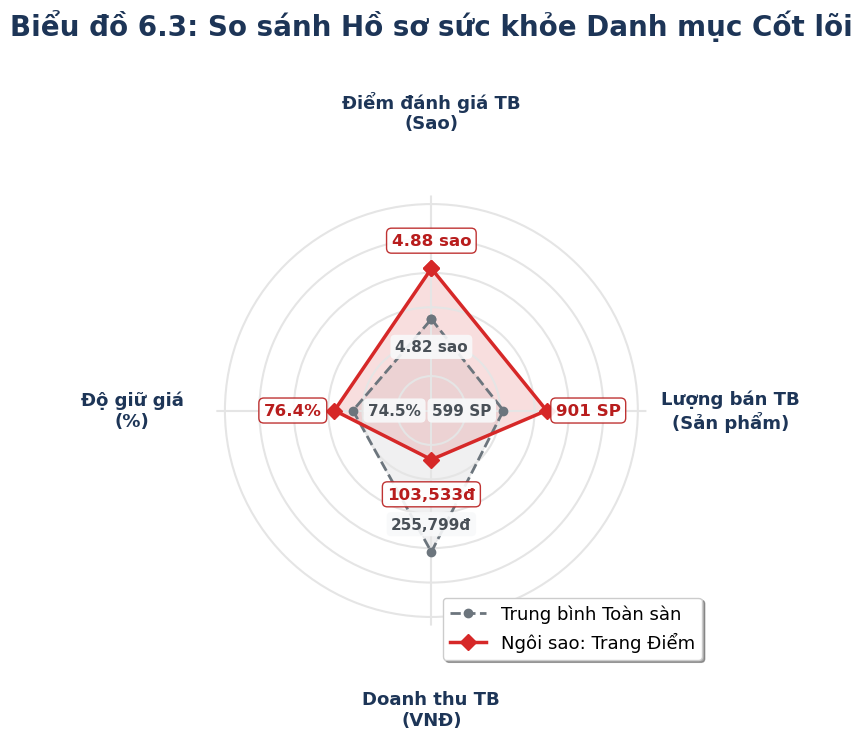

In [6]:
collection_sanpham = db['fact_products']

pipeline_stats = [
    {"$match": {
        "Danh mục": {"$type": "string", "$ne": ""},
        "Điểm đánh giá": {"$type": "number", "$ne": float('nan')},
        "Giảm giá": {"$type": "number", "$ne": float('nan')},
        "Đã bán": {"$type": "number", "$ne": float('nan')},
        "Giá": {"$type": "number", "$ne": float('nan')}
    }},
    {"$addFields": {"Doanh_thu": {"$multiply": ["$Giá", "$Đã bán"]}}},
    {"$group": {
        "_id": "$Danh mục",
        "avg_discount": {"$avg": "$Giảm giá"},
        "avg_rating": {"$avg": "$Điểm đánh giá"},
        "avg_sold": {"$avg": "$Đã bán"},
        "avg_revenue": {"$avg": "$Doanh_thu"}
    }}
]

df_stats = pd.DataFrame(list(collection_sanpham.aggregate(pipeline_stats)))
df_stats.rename(columns={"_id": "Danh mục"}, inplace=True)

df_stats['price_retention'] = 1 - df_stats['avg_discount']

market_avg_discount = df_stats['avg_discount'].mean()
star_candidates = df_stats[(df_stats['avg_rating'] > 4.8) & (df_stats['avg_discount'] < market_avg_discount)]
star_category = star_candidates.sort_values(by='avg_sold', ascending=False).iloc[0]
star_cat_name = star_category['Danh mục']

metrics = ['avg_rating', 'avg_sold', 'avg_revenue', 'price_retention']
labels = ['Điểm đánh giá TB\n(Sao)', 'Lượng bán TB\n(Sản phẩm)', 'Doanh thu TB\n(VNĐ)', 'Độ giữ giá\n(%)']

market_avg = {m: df_stats[m].mean() for m in metrics}

# 3. CHUẨN HÓA DỮ LIỆU & "KÉO DÃN" TRỤC DOANH THU
for m in metrics:
    min_val, max_val = df_stats[m].min(), df_stats[m].max()
    denominator = max_val - min_val if max_val != min_val else 1
    
    df_stats[m + '_norm'] = (df_stats[m] - min_val) / denominator
    market_avg[m + '_norm'] = (market_avg[m] - min_val) / denominator

    # --- THỦ THUẬT: NHÂN ĐÔI RIÊNG TỶ LỆ CỦA DOANH THU ---
    if m == 'avg_revenue':
        df_stats[m + '_norm'] = df_stats[m + '_norm'] * 4.0
        market_avg[m + '_norm'] = market_avg[m + '_norm'] * 4.0
        
        # Chặn trên ở mức 1.15 để lỡ có kéo dài quá thì không đâm thủng khung viền
        df_stats[m + '_norm'] = df_stats[m + '_norm'].clip(upper=1.15)
        market_avg[m + '_norm'] = min(market_avg[m + '_norm'], 1.15)

star_values_norm = df_stats[df_stats['Danh mục'] == star_cat_name][[m + '_norm' for m in metrics]].iloc[0].tolist()
star_values_norm += star_values_norm[:1] 
market_values_norm = [market_avg[m + '_norm'] for m in metrics]
market_values_norm += market_values_norm[:1]

star_values_real = df_stats[df_stats['Danh mục'] == star_cat_name][metrics].iloc[0].tolist()
market_values_real = [market_avg[m] for m in metrics]

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

# 4. VẼ BIỂU ĐỒ RADAR
fig, ax = plt.subplots(figsize=(15, 7.5), subplot_kw=dict(polar=True))

ax.plot(angles, market_values_norm, color='#6c757d', linewidth=2, linestyle='dashed', marker='o', label='Trung bình Toàn sàn')
ax.fill(angles, market_values_norm, color='#6c757d', alpha=0.1)

ax.plot(angles, star_values_norm, color='#d62828', linewidth=2.5, linestyle='solid', marker='D', markersize=8, label=f'Ngôi sao: {star_cat_name}')
ax.fill(angles, star_values_norm, color='#d62828', alpha=0.15)

def format_val(metric, val):
    if metric == 'avg_rating': return f"{val:.2f} sao"
    elif metric == 'avg_sold': return f"{int(val):,} SP"
    elif metric == 'avg_revenue': return f"{val:,.0f}đ"
    elif metric == 'price_retention': return f"{val*100:.1f}%"
    return str(val)

# Offsets để đẩy chữ không bị dính vào hình
offsets_star =   [(0, 20), (30, 0), (0, -25), (-30, 0)]  
offsets_market = [(0, -20), (-30, 0), (0, 20), (30, 0)]  

for i, angle in enumerate(angles[:-1]):
    ax.annotate(format_val(metrics[i], star_values_real[i]),
                xy=(angle, star_values_norm[i]),
                xytext=offsets_star[i], textcoords='offset points',
                color='#b81d1d', fontweight='bold', fontsize=12, ha='center', va='center',
                bbox=dict(facecolor='white', alpha=0.9, edgecolor='#b81d1d', boxstyle='round,pad=0.3', linewidth=1)) 
    
    ax.annotate(format_val(metrics[i], market_values_real[i]),
                xy=(angle, market_values_norm[i]),
                xytext=offsets_market[i], textcoords='offset points',
                color='#495057', fontweight='bold', fontsize=11, ha='center', va='center',
                bbox=dict(facecolor='#f8f9fa', alpha=0.9, edgecolor='none', boxstyle='round,pad=0.3'))

ax.set_theta_offset(np.pi / 2) 
ax.set_theta_direction(-1)     
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=13, fontweight='bold', color='#1d3557')

ax.set_ylim(0, 1.25)
ax.tick_params(pad=50)         

ax.set_yticklabels([]) 
ax.spines['polar'].set_visible(False) 
ax.grid(color='#e5e5e5', linestyle='-', linewidth=1.5)

plt.title("Biểu đồ 6.3: So sánh Hồ sơ sức khỏe Danh mục Cốt lõi", fontsize=20, fontweight='bold', color='#1d3557', pad=40)
plt.legend(loc='lower right', bbox_to_anchor=(1.15, -0.1), ncol=1, fontsize=13, frameon=True, shadow=True, facecolor='white')

plt.tight_layout()
plt.show()

### **Lý do chọn biểu đồ**
- Radar Chart (Spider Chart) được chọn vì mục tiêu ở đây là **đánh giá toàn diện "sức khỏe" của một danh mục** trên nhiều chiều cùng lúc — không phải so sánh từng chỉ số riêng lẻ mà nhìn nhận tổng thể hình dạng hồ sơ. Diện tích vùng phủ càng lớn và càng đều, danh mục đó càng cân bằng và bền vững.
- Việc chồng hai vùng (Trang Điểm vs. Toàn sàn) trên cùng một Radar cho phép nhận diện ngay **chiều nào vượt trội, chiều nào còn yếu** mà không cần đọc từng con số — đây là lợi thế mà bộ bar chart đơn lẻ không thể thay thế được khi cần truyền đạt cái nhìn tổng hợp.

### **Nhận xét**
- **Điểm đánh giá TB**: Trang Điểm đạt 4.88 sao, vượt mặt bằng toàn sàn (4.82 sao). Chênh lệch tuy nhỏ về số tuyệt đối nhưng có ý nghĩa lớn — trong một hệ thống rating đã bị "lạm phát" về điểm cao, mỗi 0.01 sao là kết quả của hàng nghìn lượt đánh giá tích cực nhất quán.
- **Lượng bán TB**: Trang Điểm bán trung bình 901 sản phẩm/shop, cao hơn ~50% so với mặt bằng chung (599 SP). Đây là minh chứng rõ ràng nhất cho sức hút của danh mục — bán chạy không phải nhờ khuyến mãi mà nhờ nhu cầu thực.
- **Doanh thu TB**: Đây là chiều duy nhất Trang Điểm **thấp hơn** toàn sàn (103,533đ so với 255,799đ). Tuy nhiên, cần đọc đúng bản chất: doanh thu trung bình thấp hơn phản ánh Trang Điểm đang phục vụ phân khúc **bình dân, giá rẻ** với tần suất mua cao — nhất quán với phát hiện từ Mục tiêu 5. Đây không phải điểm yếu mà là đặc điểm cấu trúc của danh mục.
- **Độ giữ giá**: Trang Điểm đạt 76.4% so với 74.5% của toàn sàn — tức trung bình chỉ giảm ~23.6% so với giá gốc, thấp hơn mặt bằng chung. Điều này củng cố thêm kết luận từ Biểu đồ 6.1: Trang Điểm **không cần đốt ngân sách khuyến mãi** để duy trì sức bán.

### **Kết luận**
- Hồ sơ Radar của Trang Điểm vẽ nên chân dung của một danh mục **cân bằng và bền vững**: vượt trội về rating, lượng bán và độ giữ giá — đồng thời chấp nhận doanh thu trung bình thấp hơn như một sự đánh đổi có chủ đích để tối đa hóa volume và tần suất mua.
- Ba biểu đồ 6.1, 6.2 và 6.3 kết hợp tạo thành một luận chứng hoàn chỉnh: **Trang Điểm** xứng đáng được gọi là "Danh mục Cốt lõi" vì hội tụ đủ ba yếu tố — bán chạy thực chất, chất lượng ổn định, và không phụ thuộc giảm giá.
- Khuyến nghị chiến lược: Đối với nhà bán hàng mới hoặc đang tái cơ cấu danh mục, **Trang Điểm** là lựa chọn an toàn và hiệu quả nhất để xây dựng nền tảng — tập trung vào sản phẩm bình dân chất lượng tốt, nuôi dưỡng rating tự nhiên và hạn chế phụ thuộc vào Flash Sale để bảo vệ biên lợi nhuận dài hạn.